#PySpark Install + Imports

In [ ]:
!pip -q install pyspark pandas matplotlib scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import Row

from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler, FeatureHasher
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

from pyspark.ml.classification import LogisticRegression
from pyspark.ml.regression import RandomForestRegressor

from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator,
    MulticlassClassificationEvaluator,
    RegressionEvaluator
)

from pyspark.storagelevel import StorageLevel

#Initialize Spark Session

In [ ]:
spark = (SparkSession.builder
         .appName("Business_Predictive_Analysis_Full")
         .getOrCreate())

spark.sparkContext.setLogLevel("WARN")
print("Spark:", spark.version)

Spark: 4.0.1


#Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#Input Path

In [ ]:
PATH = "/content/drive/MyDrive/CourseWork/CSV_Files/Cleaned_Output/Cleaned_business.csv"
print("PATH =", PATH)

PATH = /content/drive/MyDrive/CourseWork/CSV_Files/Cleaned_Output/Cleaned_business.csv


#Loading Dataset + Type Casting

In [ ]:
df_B1 = spark.read.csv(PATH, header=True, inferSchema=True)

cast_map = {
    "latitude": "double",
    "longitude": "double",
    "stars": "double",
    "review_count": "int",
    "is_open": "int",
    "review_count_outlier_flag": "int"
}

df_B2 = df_B1
for c, t in cast_map.items():
    if c in df_B2.columns:
        df_B2 = df_B2.withColumn(c, F.col(c).cast(t))

df_B2 = df_B2.cache()
print("Rows:", df_B2.count())
df_B2.show(5, truncate=False)
print("Type casting done")

Rows: 150346
+----------------------+-----------------------------------------+-----------+-----+--------+----------+-----+------------+-------+----------------+-----------------+-------------------------+
|business_id           |name                                     |city       |state|latitude|longitude |stars|review_count|is_open|primary_category|price_range_label|review_count_outlier_flag|
+----------------------+-----------------------------------------+-----------+-----+--------+----------+-----+------------+-------+----------------+-----------------+-------------------------+
|--LC8cIrALInl2vyo701tg|Studio G Salon                           |Tampa      |FL   |28.06589|-82.5593  |5.0  |8           |1      |Hair Salons     |Unknown          |0                        |
|--rS-rnOIZxoiDA8yctWpQ|Publix GreenWise Market                  |Tampa      |FL   |27.94329|-82.45016 |5.0  |8           |1      |Organic Stores  |Unknown          |0                        |
|--zb12mw2YK-7j6UaHzm8

#Predictive Analysis

##Classification : Logical Regression

###Modelling Setup

In [ ]:
# For Classification (High Rating)
# label = 1 if stars >= 4 else 0
numeric_features_clf = [c for c in ["latitude","longitude","review_count","review_count_outlier_flag"] if c in df_B2.columns]
categorical_features_clf = [c for c in ["city","state","primary_category","price_range_label"] if c in df_B2.columns]

# Remove categorical columns with <2 distinct values (same logic you had)
for col_name in list(categorical_features_clf):
    distinct_count = df_B2.select(col_name).distinct().count()
    if distinct_count < 2:
        categorical_features_clf.remove(col_name)

needed_cols_clf = ["stars"] + numeric_features_clf + categorical_features_clf

df_B3_clf = (df_B2
    .where(F.col("stars").isNotNull())
    .select(*needed_cols_clf)
    .dropna(subset=needed_cols_clf)
    .withColumn("label", (F.col("stars") >= F.lit(4.0)).cast("int"))
    .cache()
)

print("Model rows (Classification) after dropna:", df_B3_clf.count())
print("Numeric features:", numeric_features_clf)
print("Categorical features:", categorical_features_clf)

# Train/Test split
train_clf, test_clf = df_B3_clf.randomSplit([0.8, 0.2], seed=12)

Model rows (Classification) after dropna: 150346
Numeric features: ['latitude', 'longitude', 'review_count', 'review_count_outlier_flag']
Categorical features: ['city', 'state', 'primary_category']


###Target: High Rating (1 if stars >= 4.0 else 0)

In [ ]:
# Encode categoricals
indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in categorical_features_clf]
encoders = [OneHotEncoder(inputCol=f"{c}_idx", outputCol=f"{c}_ohe") for c in categorical_features_clf]

# Assemble + scale
assembled_inputs = numeric_features_clf + [f"{c}_ohe" for c in categorical_features_clf]
assembler = VectorAssembler(inputCols=assembled_inputs, outputCol="features_raw")
scaler = StandardScaler(inputCol="features_raw", outputCol="features", withMean=False, withStd=True)

lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=100)
clf_pipe = Pipeline(stages=indexers + encoders + [assembler, scaler, lr])

# Hyperparameter Grid
clf_grid = (ParamGridBuilder()
    .addGrid(lr.regParam, [0.001, 0.02, 0.3])
    .addGrid(lr.elasticNetParam, [0.0, 0.5, 1.0])
    .addGrid(lr.maxIter, [50, 100])
    .build()
)

# Cross Validation (choose best by ROC-AUC)
auc_eval = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

clf_cv = CrossValidator(
    estimator=clf_pipe,
    estimatorParamMaps=clf_grid,
    evaluator=auc_eval,
    numFolds=3,
    parallelism=2,
    seed=12
)

# Train + Predict
clf_cv_model = clf_cv.fit(train_clf)
clf_pred = clf_cv_model.transform(test_clf)

# Metrics
roc_auc = auc_eval.evaluate(clf_pred)

f1 = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="f1"
).evaluate(clf_pred)

recall_not_high = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="recallByLabel", metricLabel=0
).evaluate(clf_pred)

recall_high = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="recallByLabel", metricLabel=1
).evaluate(clf_pred)

best_lr = clf_cv_model.bestModel.stages[-1]
best_params = f"regParam={best_lr.getRegParam()}, elasticNet={best_lr.getElasticNetParam()}, maxIter={best_lr.getMaxIter()}"

print("\nCLASSIFICATION RESULTS (Business: High Rating)")
print("Best params →", best_params)
print(f"Metrics → ROC-AUC={roc_auc:.3f}, F1={f1:.3f}, Recall_NotHigh(0)={recall_not_high:.3f}, Recall_High(1)={recall_high:.3f}")

print("\nConfusion Matrix (label=actual, prediction=predicted):")
clf_pred.groupBy("label","prediction").count().orderBy("label","prediction").show()

# Final Output table
df_clf_summary = spark.createDataFrame([Row(
    Model="LogisticRegression (CV)",
    Task="Classification",
    Target="HIGH_RATING (1 if stars>=4.0)",
    Seed=12,
    Best_Params=best_params,
    ROC_AUC=float(roc_auc),
    F1=float(f1),
    Recall_NotHigh=float(recall_not_high),
    Recall_High=float(recall_high)
)])
df_clf_summary.show(truncate=False)


CLASSIFICATION RESULTS (Business: High Rating)
Best params → regParam=0.001, elasticNet=1.0, maxIter=50
Metrics → ROC-AUC=0.680, F1=0.630, Recall_NotHigh(0)=0.624, Recall_High(1)=0.636

Confusion Matrix (label=actual, prediction=predicted):
+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|    0|       0.0| 9423|
|    0|       1.0| 5668|
|    1|       0.0| 5493|
|    1|       1.0| 9594|
+-----+----------+-----+

+-----------------------+--------------+-----------------------------+----+------------------------------------------+------------------+------------------+------------------+------------------+
|Model                  |Task          |Target                       |Seed|Best_Params                               |ROC_AUC           |F1                |Recall_NotHigh    |Recall_High       |
+-----------------------+--------------+-----------------------------+----+------------------------------------------+------------------+------------------+-----------

##Classification Model Evaluation

###1.ROC Curve

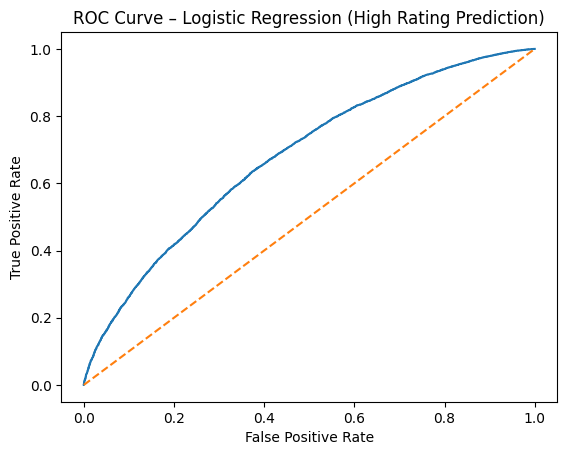

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType
from pyspark.sql.functions import udf
from pyspark.ml.linalg import VectorUDT, DenseVector, SparseVector

# When passed to a Python UDF, becomes a DenseVector or SparseVector object.
def get_positive_class_probability(probability_vector):
    if isinstance(probability_vector, DenseVector):
        return float(probability_vector[1]) # Get the probability for class 1
    elif isinstance(probability_vector, SparseVector):
        # For sparse vectors,safer to convert to dense array if unsure of index presence
        return float(probability_vector.toArray()[1])
    return None

# Register the UDF
extract_prob_udf = udf(get_positive_class_probability, DoubleType())

# Prepare data for roc_curve
roc_data = clf_pred.select(
    extract_prob_udf(F.col("probability")).alias("probability"),
    F.col("label").alias("true_label")
).toPandas()

# Calculate ROC curve points using scikit-learn
fpr, tpr, thresholds = roc_curve(roc_data["true_label"], roc_data["probability"])

plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Logistic Regression (High Rating Prediction)")
plt.show()

###2. Confusion Metrix

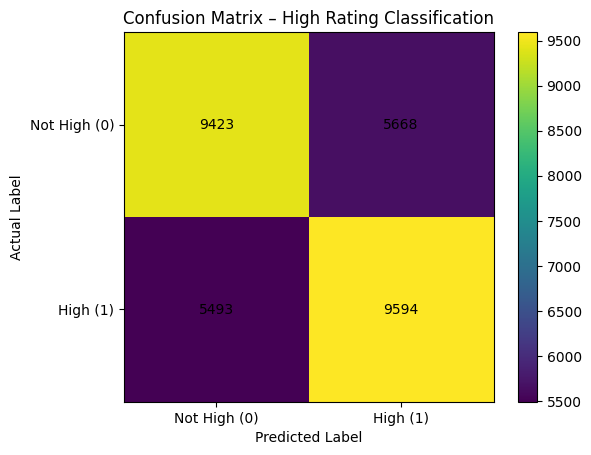

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create confusion matrix table
cm_df = (
    clf_pred
    .groupBy("label", "prediction")
    .count()
    .toPandas()
)

cm = np.zeros((2, 2), dtype=int)

for _, row in cm_df.iterrows():
    cm[int(row["label"]), int(row["prediction"])] = row["count"]

plt.figure()
plt.imshow(cm)
plt.xticks([0, 1], ["Not High (0)", "High (1)"])
plt.yticks([0, 1], ["Not High (0)", "High (1)"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix – High Rating Classification")
plt.colorbar()
plt.show()


###Precision-Recall Curve

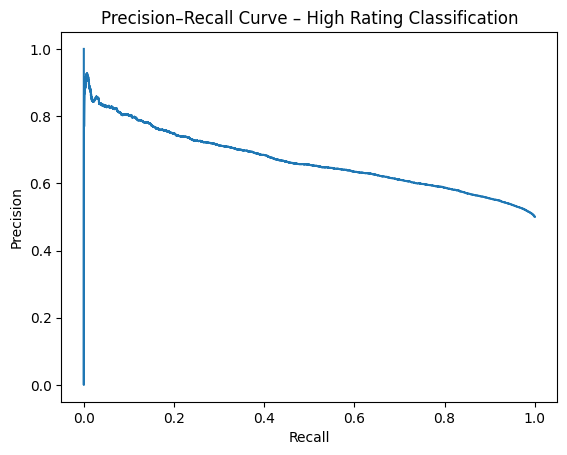

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
from pyspark.sql import functions as F

# Reuse the UDF defined in imTbkIMOem_9 to extract positive class probabilities
# The UDF extracts the probability of the positive class (class 1)
# The 'probability' column from LogisticRegression is a VectorUDT
# When passed to a Python UDF, it becomes a DenseVector or SparseVector object.
def get_positive_class_probability(probability_vector):
    if isinstance(probability_vector, DenseVector):
        return float(probability_vector[1]) # Get the probability for class 1
    elif isinstance(probability_vector, SparseVector):
        return float(probability_vector.toArray()[1])
    return None

extract_prob_udf = udf(get_positive_class_probability, DoubleType())

# Prepare data for precision_recall_curve
pr_data = clf_pred.select(
    extract_prob_udf(F.col("probability")).alias("probability"),
    F.col("label").alias("true_label")
).toPandas()

# Calculate Precision-Recall curve points using scikit-learn
precision, recall, thresholds = precision_recall_curve(
    pr_data["true_label"],
    pr_data["probability"]
)

plt.figure()
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve – High Rating Classification")
plt.show()

##Regression: Random Forest

###Target: y=log1p(1+review count)

In [ ]:
from pyspark.sql import functions as F, Row
from pyspark.storagelevel import StorageLevel

from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, FeatureHasher
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.evaluation import RegressionEvaluator


#Create target: y = log(1 + review_count)
df_reg = (df_B2
    .where(F.col("review_count").isNotNull())
    .withColumn("review_count", F.col("review_count").cast("double"))
    .withColumn("y", F.log1p(F.col("review_count")))
)

#Feature Columns (exclude review count and stars for leakage)
numeric_cols = [c for c in ["latitude", "longitude", "is_open", "review_count_outlier_flag"] if c in df_reg.columns]
categorical_cols = [c for c in ["city", "state", "primary_category", "price_range_label"] if c in df_reg.columns]

needed = ["y"] + numeric_cols + categorical_cols
df_reg = df_reg.select(*needed).dropna(subset=needed)

print("Target: y = log(1 + review_count)")
print("Numeric features:", numeric_cols)
print("Categorical features (hashed):", categorical_cols)
print("Rows after dropna:", df_reg.count())

#Train/Test split
train_reg, test_reg = df_reg.randomSplit([0.8, 0.2], seed=12)

#Persist to prevent recomputation during CV
train_reg = train_reg.persist(StorageLevel.MEMORY_AND_DISK)
test_reg  = test_reg.persist(StorageLevel.MEMORY_AND_DISK)
_ = train_reg.count()
_ = test_reg.count()

#Feature pipeline (hash categoricals -> fixed size vector)
hasher = FeatureHasher(
    inputCols=categorical_cols,
    outputCol="cat_hashed",
    numFeatures=256
)

num_assembler = VectorAssembler(
    inputCols=numeric_cols,
    outputCol="num_vec",
    handleInvalid="skip"
)

final_assembler = VectorAssembler(
    inputCols=["num_vec", "cat_hashed"],
    outputCol="features",
    handleInvalid="skip"
)

#Model
rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="y",
    seed=12
)

reg_pipe = Pipeline(stages=[hasher, num_assembler, final_assembler, rf])

#Hyperparameter grid
reg_grid = (ParamGridBuilder()
    .addGrid(rf.numTrees, [50, 100])
    .addGrid(rf.maxDepth, [8, 12])
    .addGrid(rf.maxBins, [48])
    .build()
)

#Cross-validation (choose best by RMSE)
rmse_eval = RegressionEvaluator(labelCol="y", predictionCol="prediction", metricName="rmse")

reg_cv = CrossValidator(
    estimator=reg_pipe,
    estimatorParamMaps=reg_grid,
    evaluator=rmse_eval,
    numFolds=3,
    parallelism=1,
    seed=12
)

# Train + predict
reg_cv_model = reg_cv.fit(train_reg)
reg_pred = reg_cv_model.transform(test_reg)

#Metrics (RMSE, MAE, R2)
rmse = RegressionEvaluator(labelCol="y", predictionCol="prediction", metricName="rmse").evaluate(reg_pred)
mae  = RegressionEvaluator(labelCol="y", predictionCol="prediction", metricName="mae").evaluate(reg_pred)
r2   = RegressionEvaluator(labelCol="y", predictionCol="prediction", metricName="r2").evaluate(reg_pred)

best = reg_cv_model.bestModel.stages[-1]
best_params = f"numTrees={best.getNumTrees}, maxDepth={best.getMaxDepth}, maxBins={best.getMaxBins}"

print("\nREGRESSION RESULTS (RF on log1p(review_count)) — leakage-safe")
print("Best params →", best_params)
print(f"Metrics → RMSE={rmse:.3f}, MAE={mae:.3f}, R2={r2:.3f}")


#Final Output table
df_reg_summary = spark.createDataFrame([Row(
    Model="RandomForestRegressor (CV)",
    Task="Regression",
    Target="y = log1p(review_count)",
    Seed=12,
    Best_Params=best_params,
    RMSE=float(rmse),
    MAE=float(mae),
    R2=float(r2)
)])
df_reg_summary.show(truncate=False)

#Interpret predictions back to approx review_count
# review_count ≈ exp(prediction) - 1
reg_pred.select(
    F.col("y").alias("actual_log_reviews"),
    F.col("prediction").alias("pred_log_reviews"),
    F.expm1(F.col("prediction")).alias("pred_review_count_approx")
).show(10, truncate=False)

# Cleanup persisted data
train_reg.unpersist()
test_reg.unpersist()

Target: y = log(1 + review_count)
Numeric features: ['latitude', 'longitude', 'is_open', 'review_count_outlier_flag']
Categorical features (hashed): ['city', 'state', 'primary_category', 'price_range_label']
Rows after dropna: 150346

REGRESSION RESULTS (RF on log1p(review_count)) — leakage-safe
Best params → numTrees=100, maxDepth=<bound method _DecisionTreeParams.getMaxDepth of RandomForestRegressionModel: uid=RandomForestRegressor_58ea84591dbf, numTrees=100, numFeatures=260>, maxBins=<bound method _DecisionTreeParams.getMaxBins of RandomForestRegressionModel: uid=RandomForestRegressor_58ea84591dbf, numTrees=100, numFeatures=260>
Metrics → RMSE=0.657, MAE=0.519, R2=0.426
+--------------------------+----------+-----------------------+----+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

DataFrame[y: double, latitude: double, longitude: double, is_open: int, review_count_outlier_flag: int, city: string, state: string, primary_category: string, price_range_label: string]

##Regression Model Evaluation

###Actual vs Predicted (log scale)

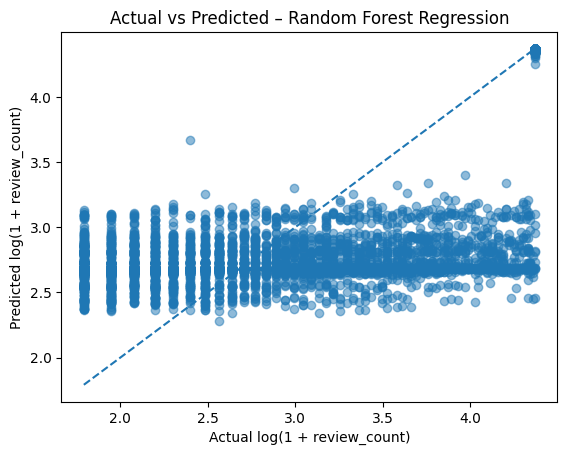

In [ ]:
import matplotlib.pyplot as plt

plot_df = (
    reg_pred
    .select("y", "prediction")
    .sample(fraction=0.2, seed=12)
    .toPandas()
)

plt.figure()
plt.scatter(plot_df["y"], plot_df["prediction"], alpha=0.5)
plt.plot(
    [plot_df["y"].min(), plot_df["y"].max()],
    [plot_df["y"].min(), plot_df["y"].max()],
    linestyle="--"
)
plt.xlabel("Actual log(1 + review_count)")
plt.ylabel("Predicted log(1 + review_count)")
plt.title("Actual vs Predicted – Random Forest Regression")
plt.show()


###Residuals vs Predicted (log scale)

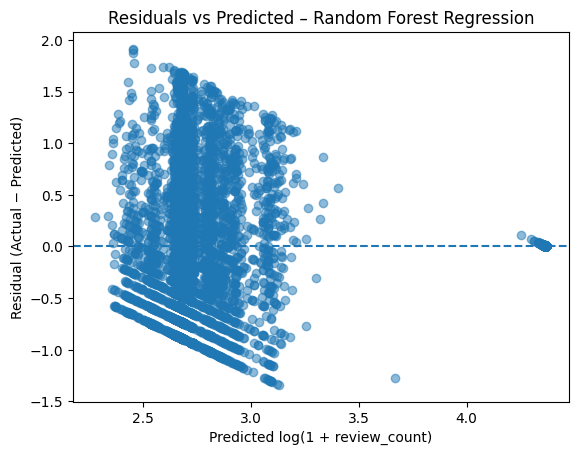

In [ ]:
import numpy as np
from pyspark.sql import functions as F

residual_df = (
    reg_pred
    .select(
        F.col("prediction"),
        (F.col("y") - F.col("prediction")).alias("residual")
    )
    .sample(fraction=0.2, seed=12)
    .toPandas()
)

plt.figure()
plt.scatter(residual_df["prediction"], residual_df["residual"], alpha=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted log(1 + review_count)")
plt.ylabel("Residual (Actual − Predicted)")
plt.title("Residuals vs Predicted – Random Forest Regression")
plt.show()


###Actual vs Predicted (original scale)

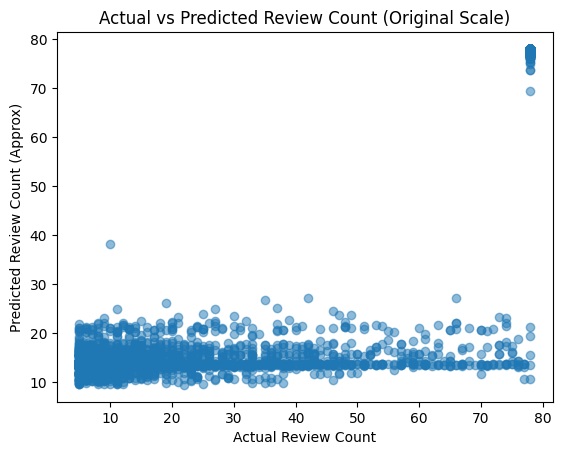

In [ ]:
orig_scale_df = (
    reg_pred
    .select(
        F.expm1("y").alias("actual_reviews"),
        F.expm1("prediction").alias("predicted_reviews")
    )
    .sample(fraction=0.1, seed=12)
    .toPandas()
)

plt.figure()
plt.scatter(
    orig_scale_df["actual_reviews"],
    orig_scale_df["predicted_reviews"],
    alpha=0.5
)
plt.xlabel("Actual Review Count")
plt.ylabel("Predicted Review Count (Approx)")
plt.title("Actual vs Predicted Review Count (Original Scale)")
plt.show()
